
📊 Processing Dataset: l11p/COCOQA-restval-ICQA (cocoqa_restval_icqa)

🔍 Pooling Method: last
--------------------------------------------------------------------------------
✅ Saved plot to ../plots/models_similarity/cocoqa_restval_icqa_last_neighborhood_overlap_model_comparison.png


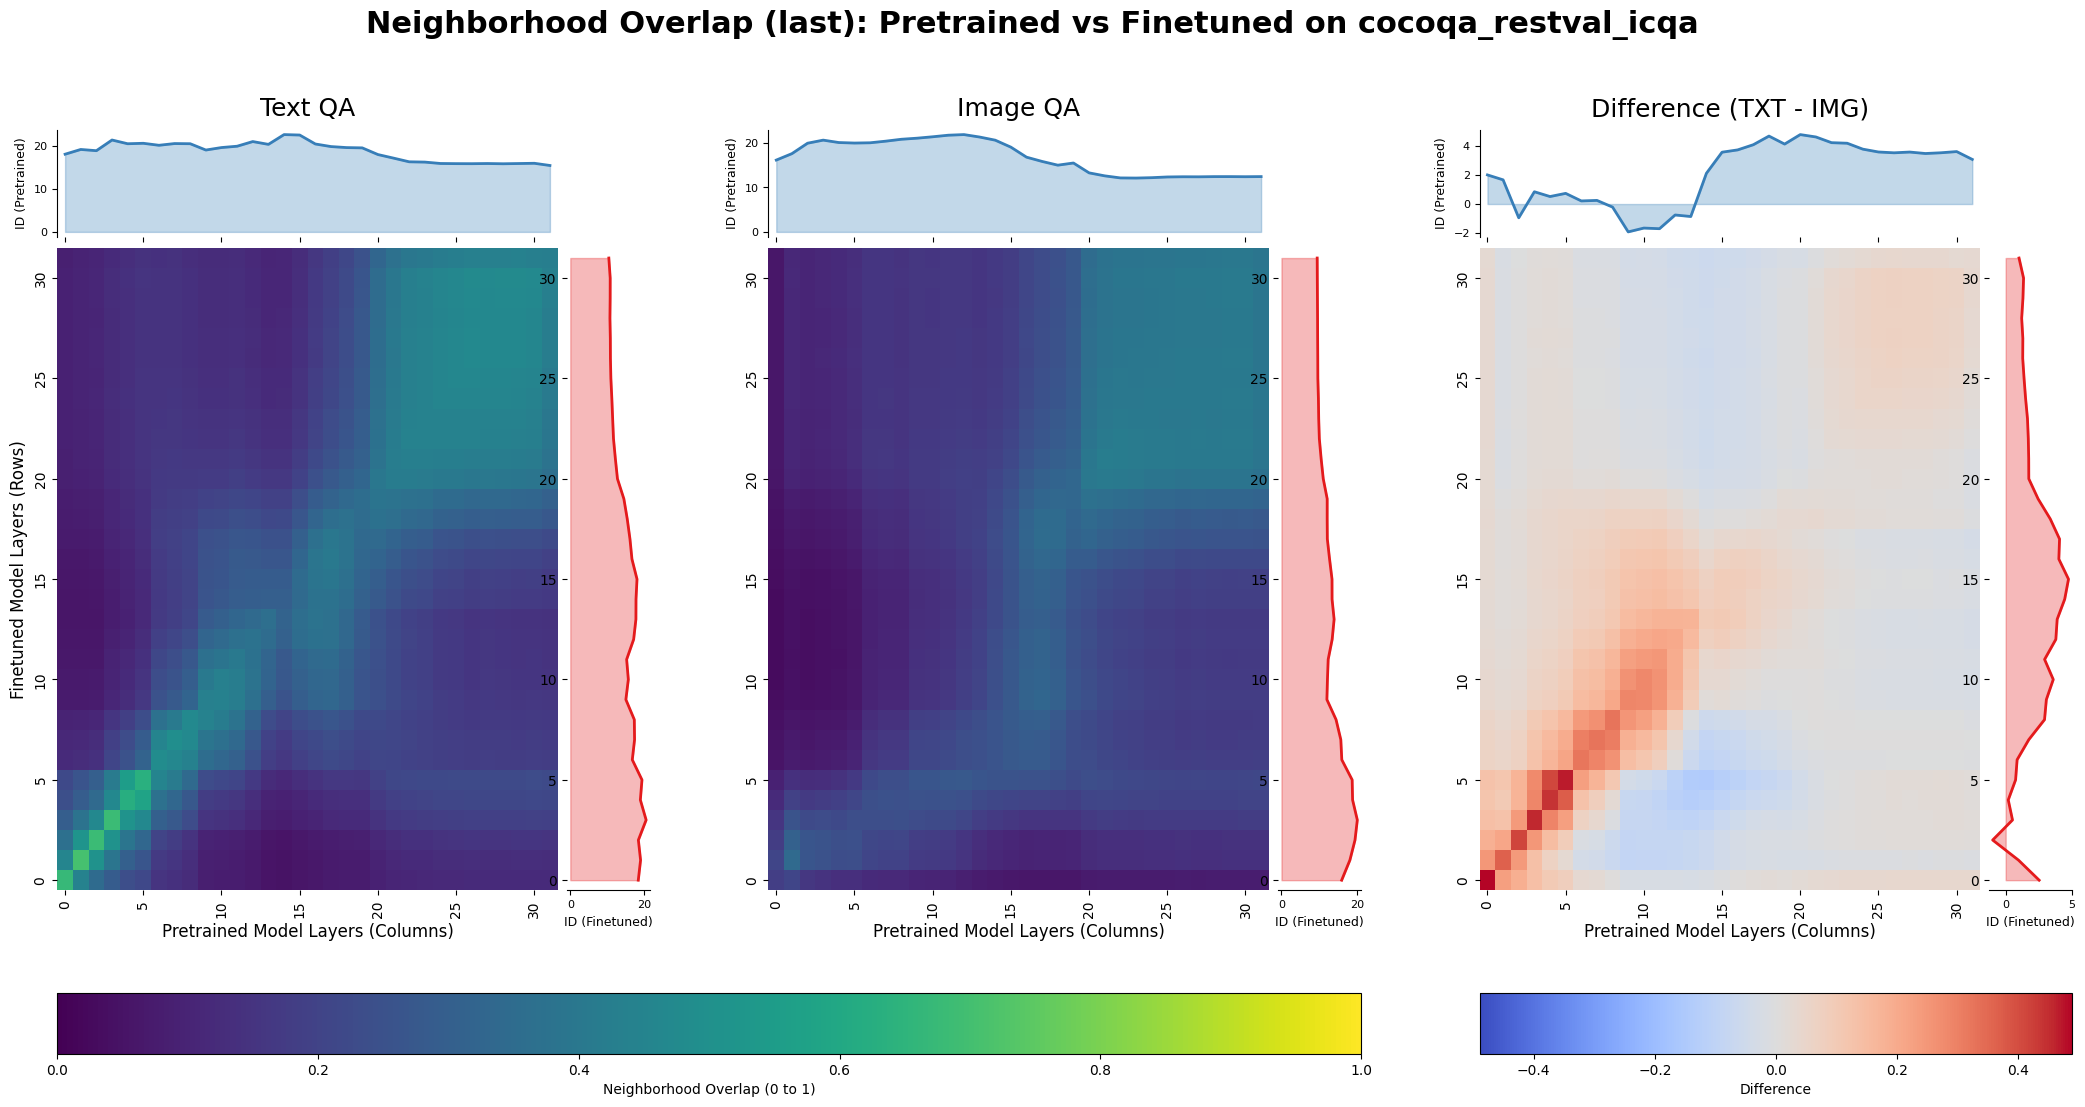

✅ Saved plot to ../plots/models_similarity/cocoqa_restval_icqa_last_linear_cka_model_comparison.png


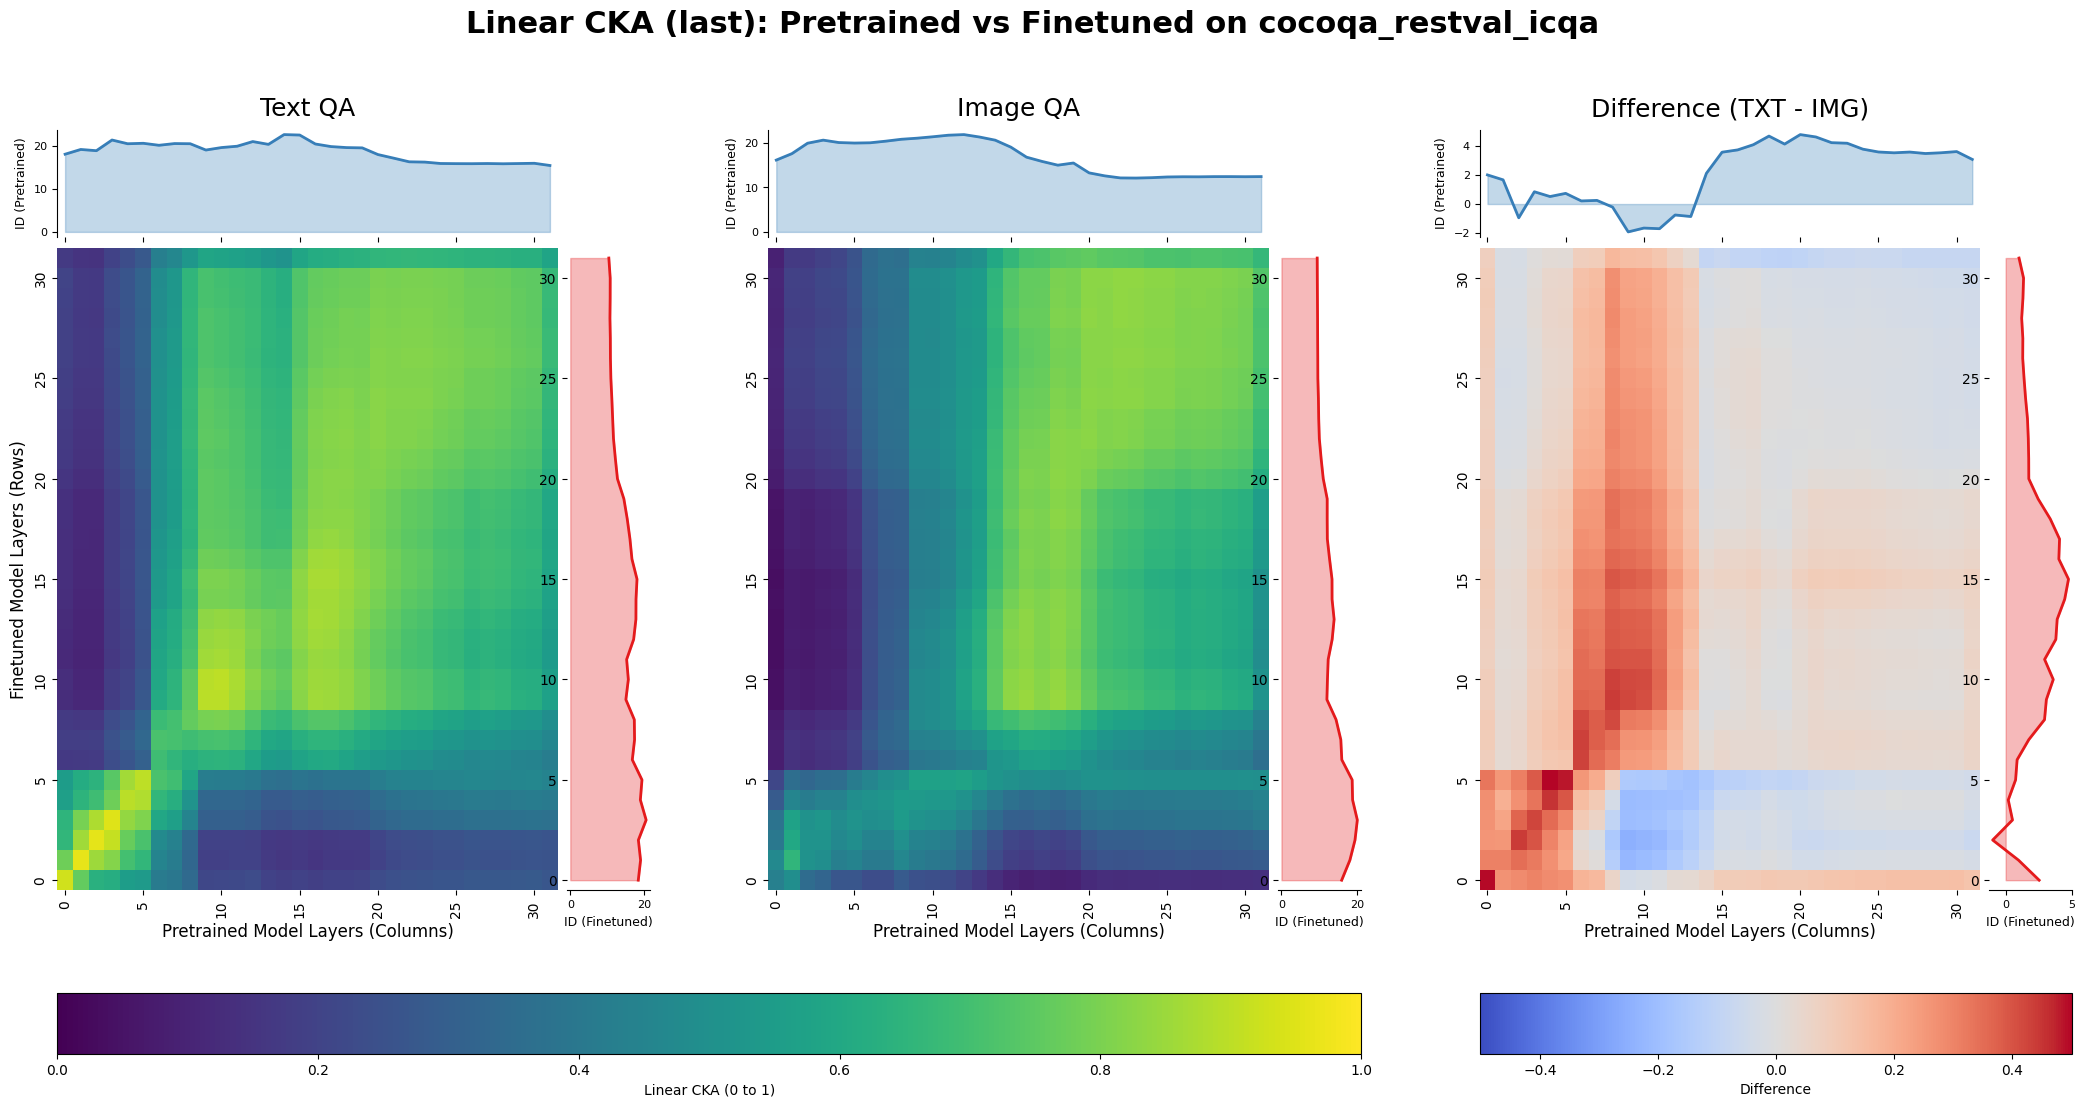

⚠️  Warning: Could not load similarity file: cocoqa_restval_icqa_txt_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors
    Error: No such file or directory: "../results/model_comparison/similarities/cocoqa_restval_icqa_txt_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors"
⚠️  Warning: Could not load similarity file: cocoqa_restval_icqa_img_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors
    Error: No such file or directory: "../results/model_comparison/similarities/cocoqa_restval_icqa_img_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors"
❌ Skipping plot for ID Correlation: Missing similarity data.
✅ Saved plot to ../plots/models_similarity/cocoqa_restval_icqa_last_information_imbalance_model_comparison.png


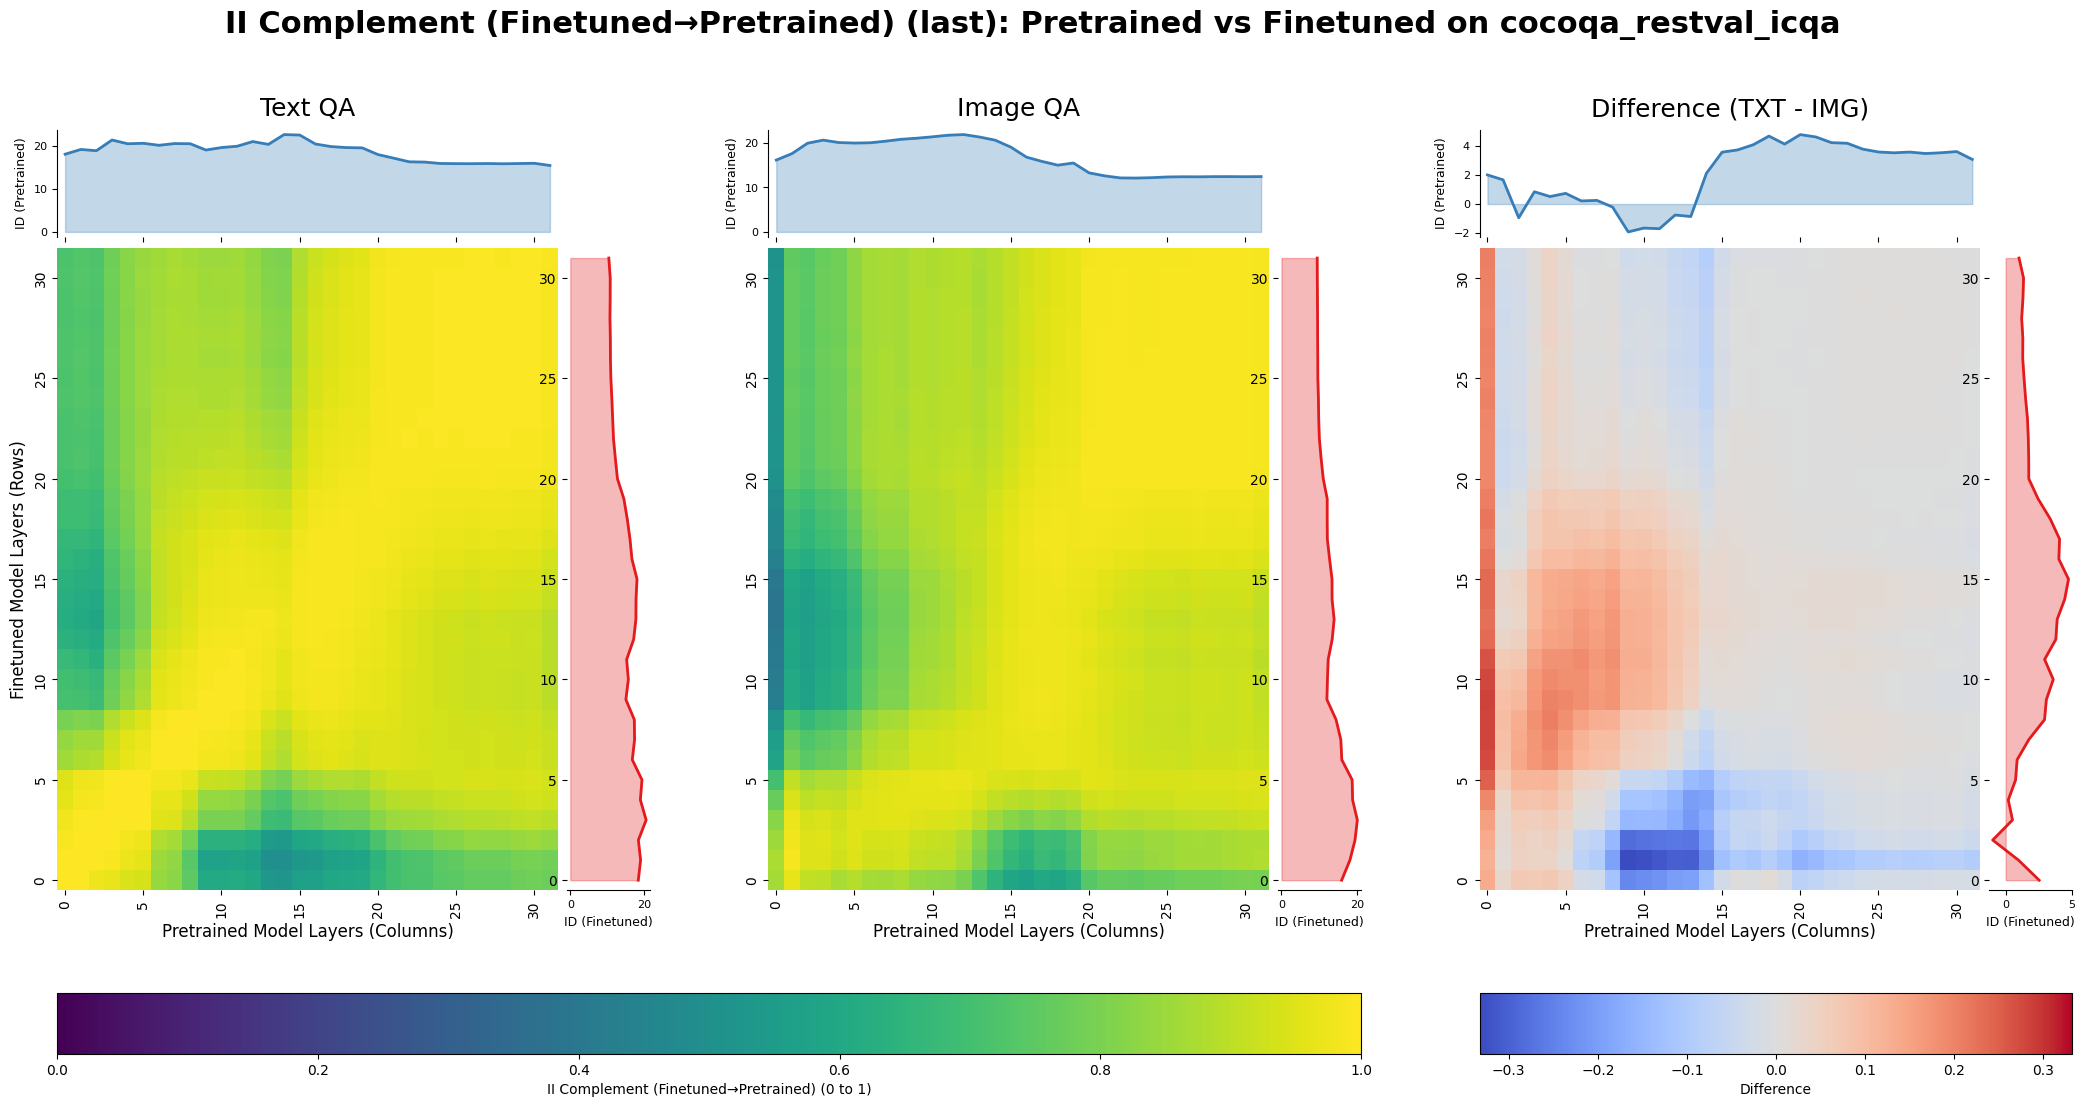

✅ Saved plot to ../plots/models_similarity/cocoqa_restval_icqa_last_information_imbalance_reversed_model_comparison.png


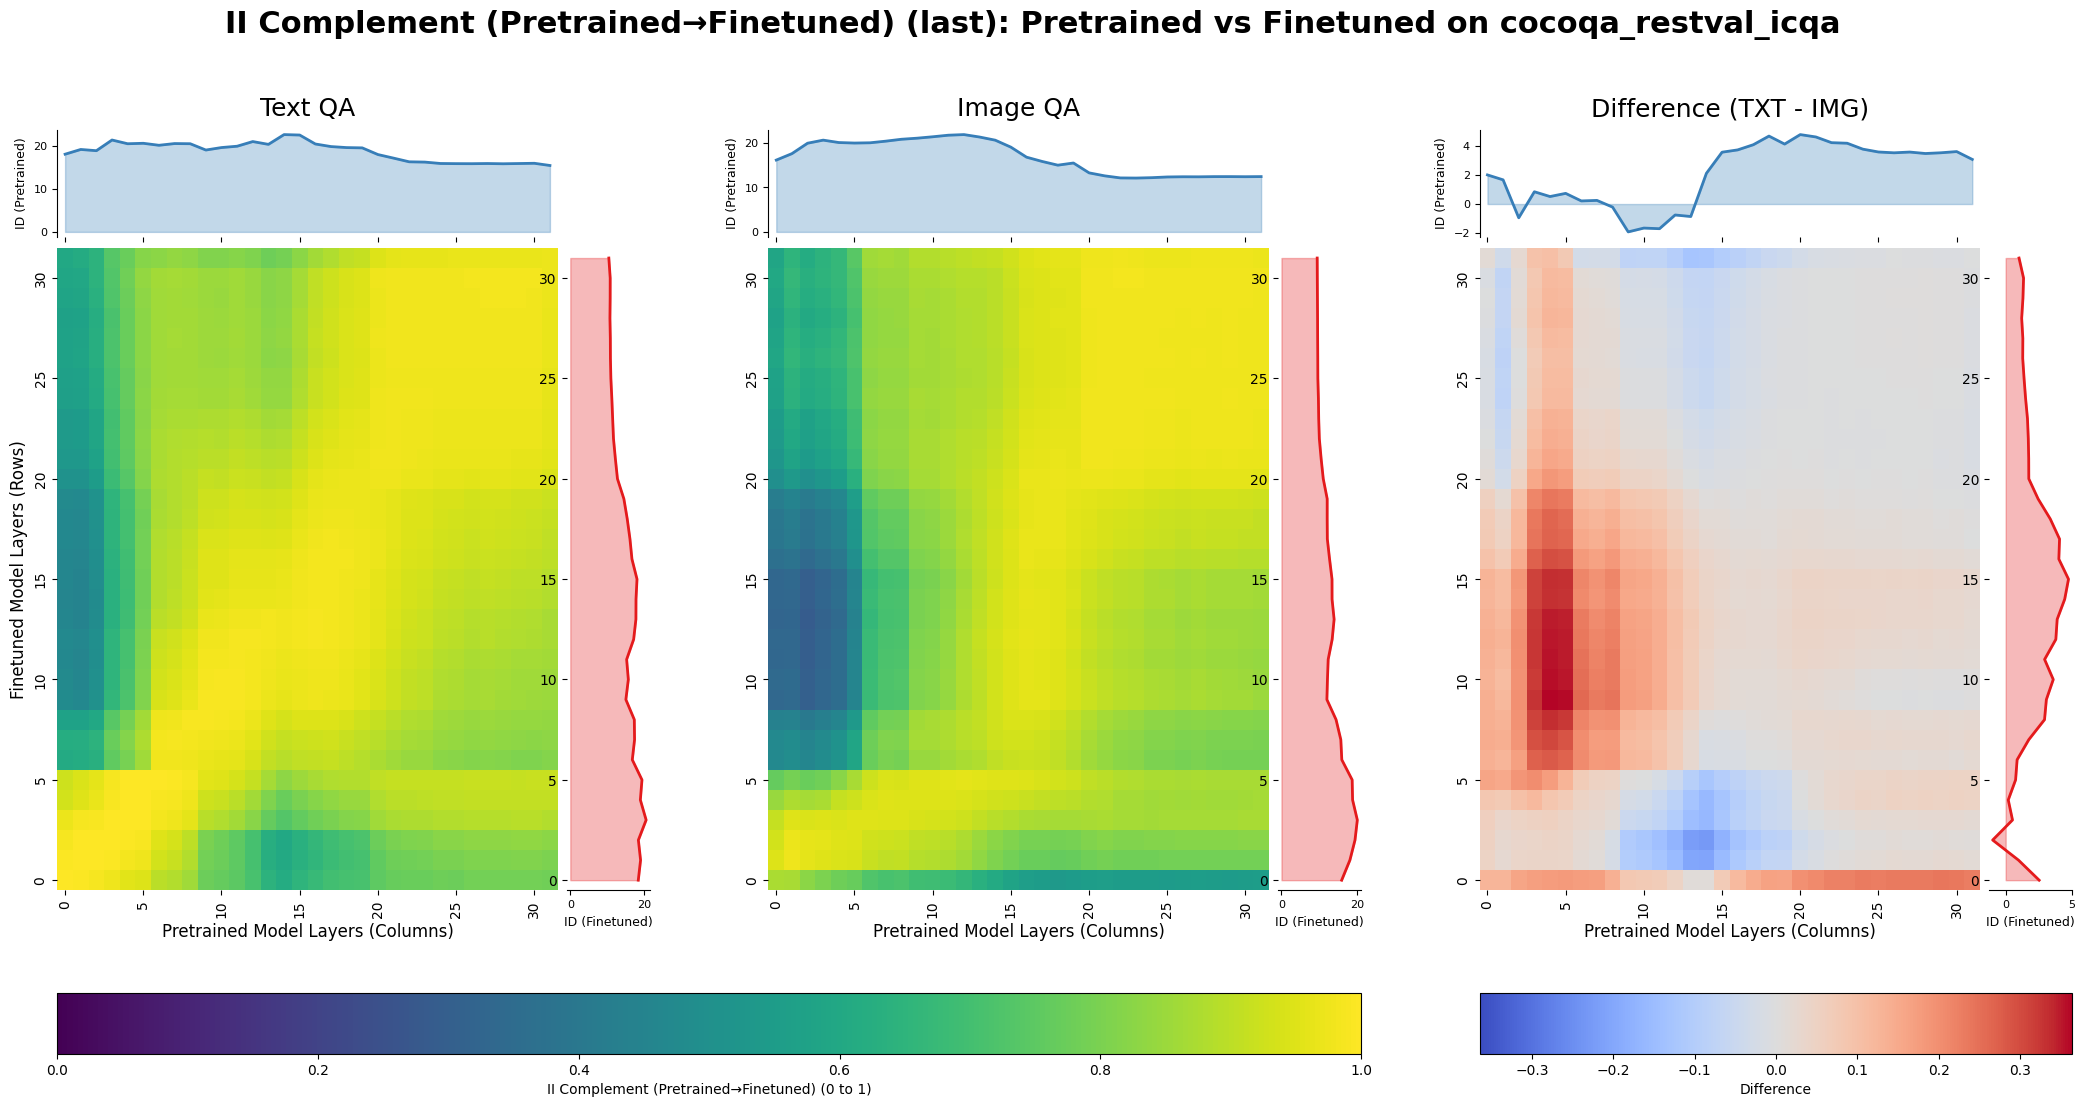

✅ Saved plot to ../plots/models_similarity/cocoqa_restval_icqa_last_information_imbalance_mean_model_comparison.png


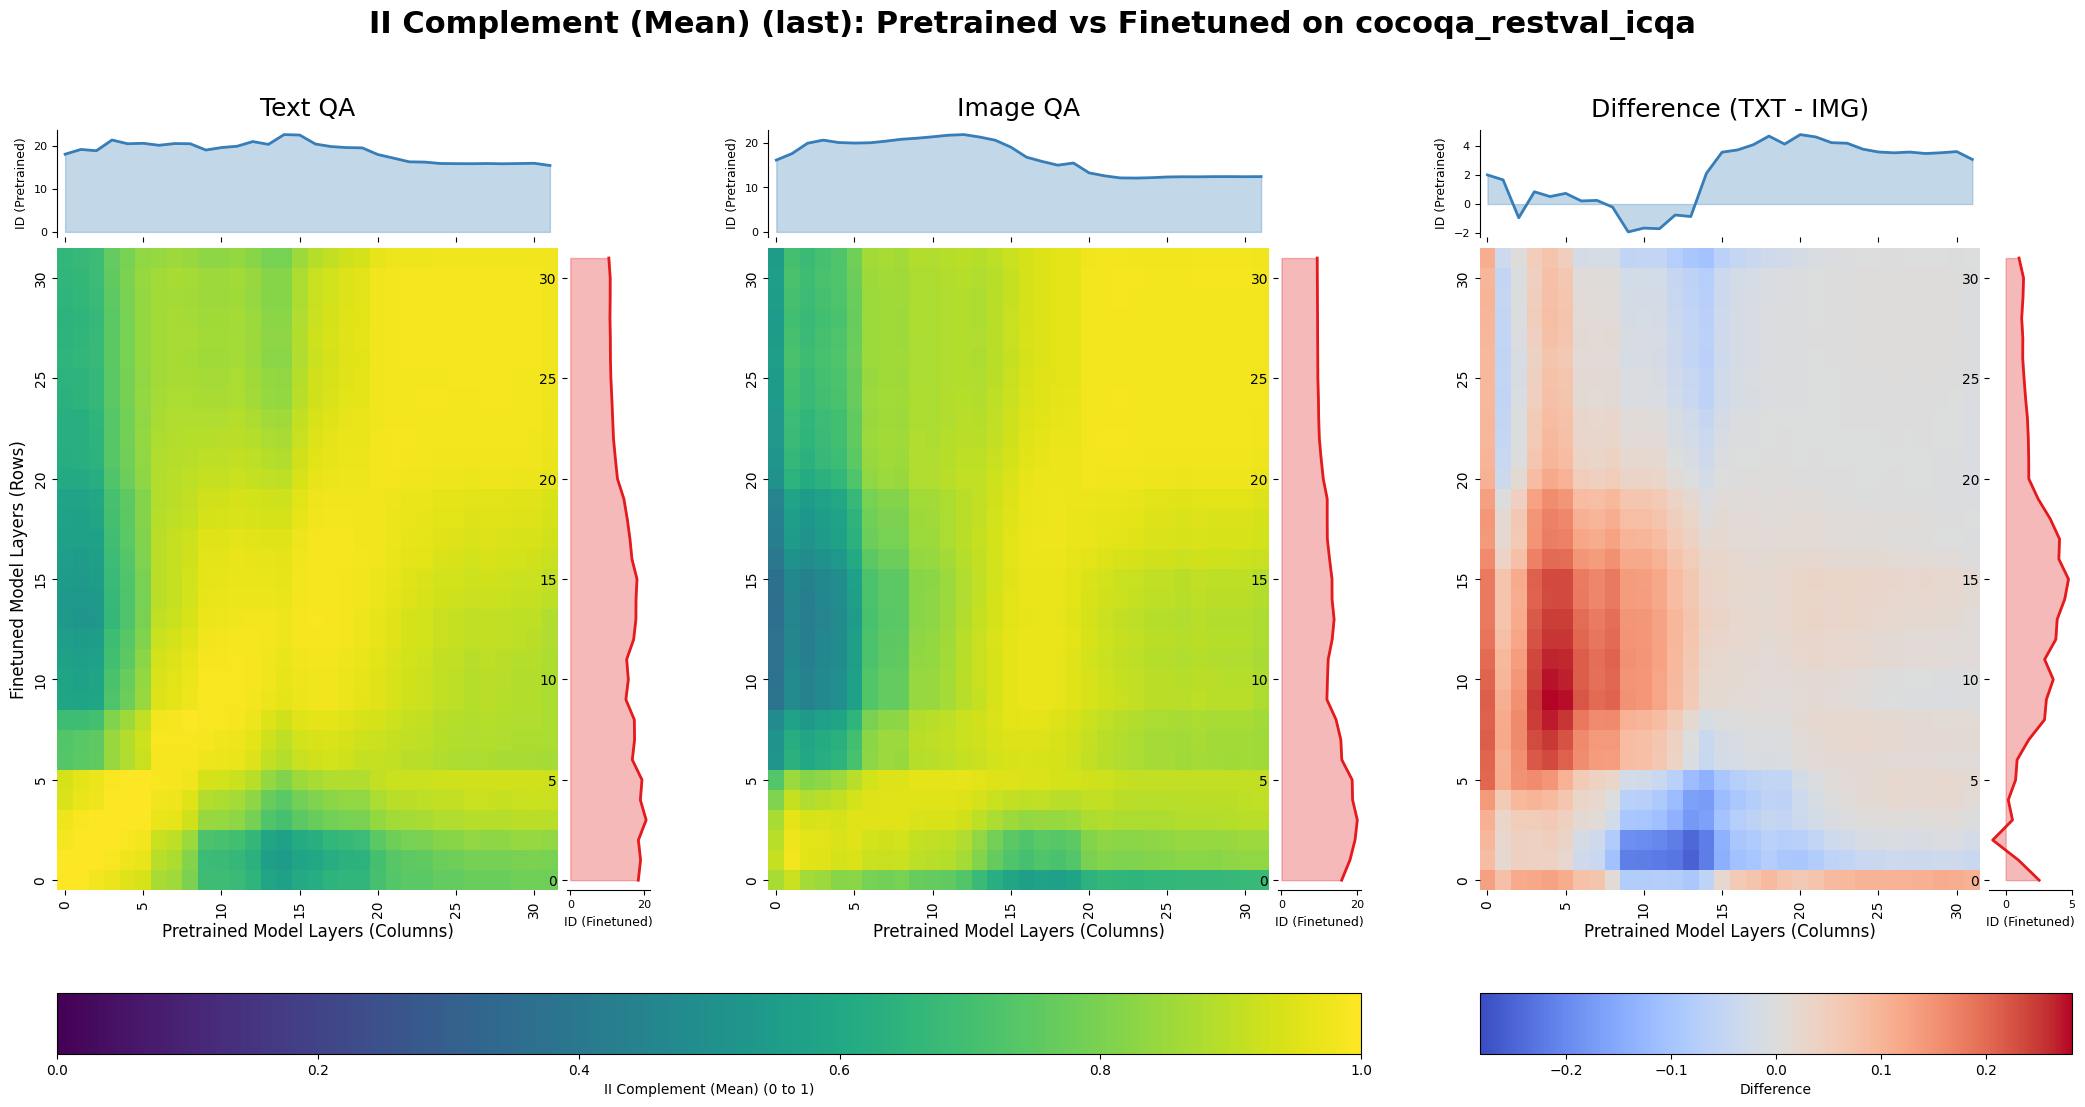

⚠️  Warning: Could not load similarity file: cocoqa_restval_icqa_txt_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors
    Error: No such file or directory: "../results/model_comparison/similarities/cocoqa_restval_icqa_txt_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors"
⚠️  Warning: Could not load similarity file: cocoqa_restval_icqa_img_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors
    Error: No such file or directory: "../results/model_comparison/similarities/cocoqa_restval_icqa_img_llava-1.5-7b-hf_vs_llava-v1.5-7b-pretrained-liuhaotian_last_id_correlation.safetensors"
✅ Saved diagonal comparison to ../plots/models_similarity/cocoqa_restval_icqa_last_diagonals_comparison.png


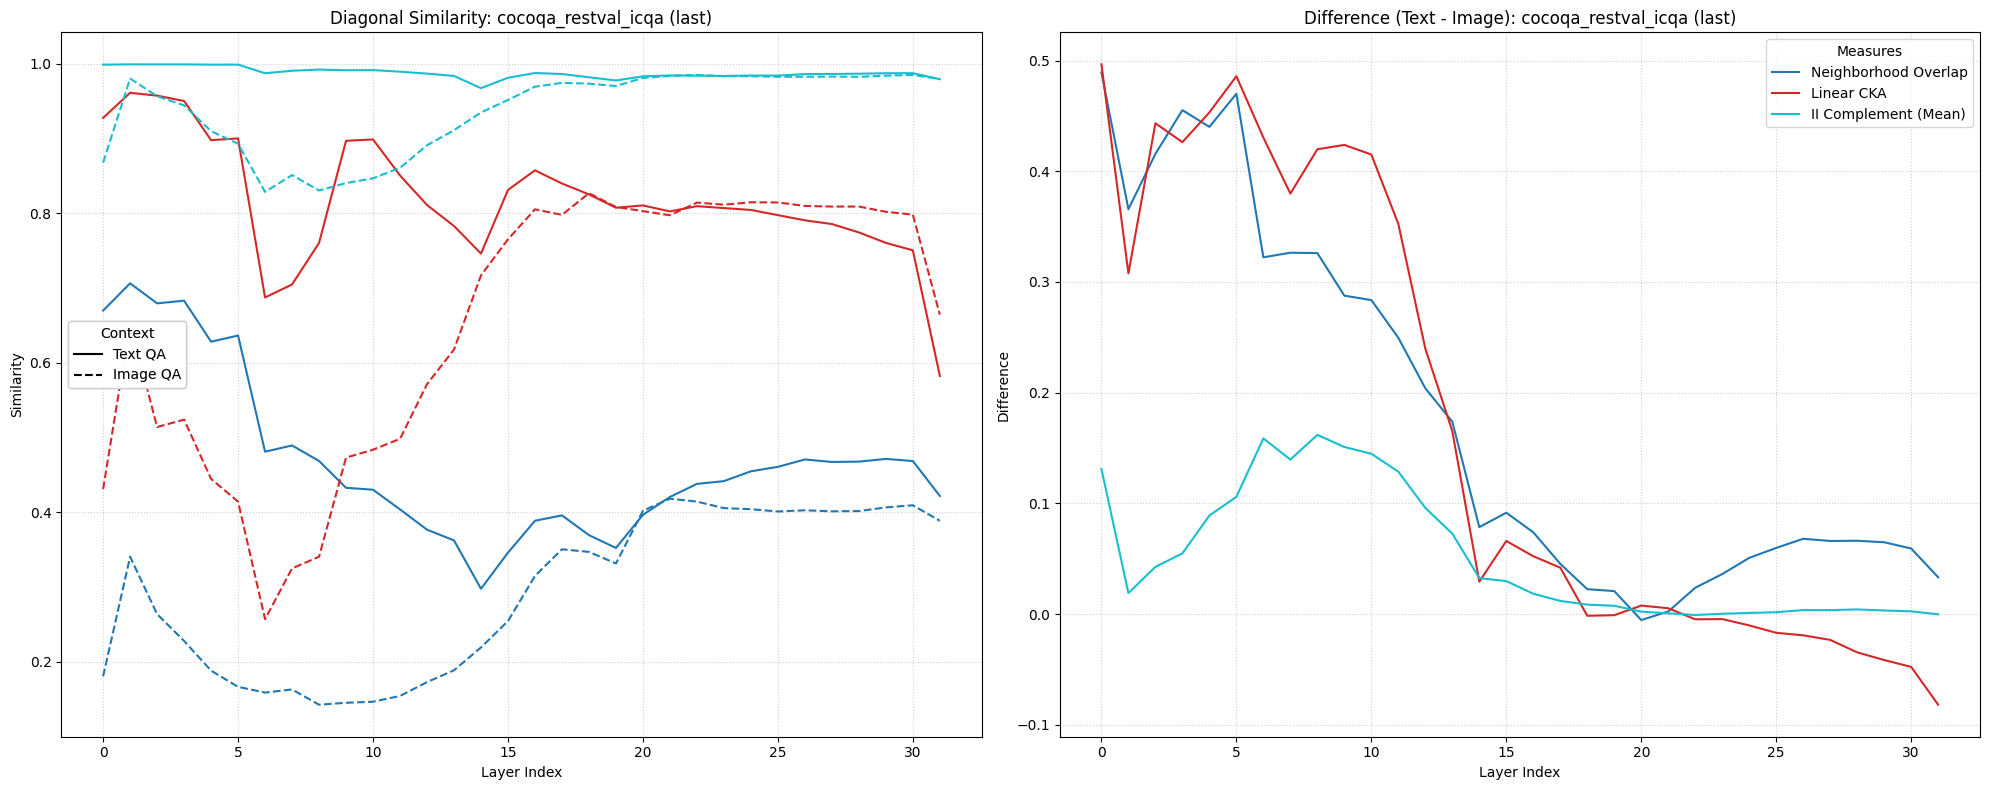


📊 Processing Dataset: l11p/VQAv2-COCO-restval-ICQ (vqav2_coco_restval_icq)

🔍 Pooling Method: last
--------------------------------------------------------------------------------
✅ Saved plot to ../plots/models_similarity/vqav2_coco_restval_icq_last_neighborhood_overlap_model_comparison.png


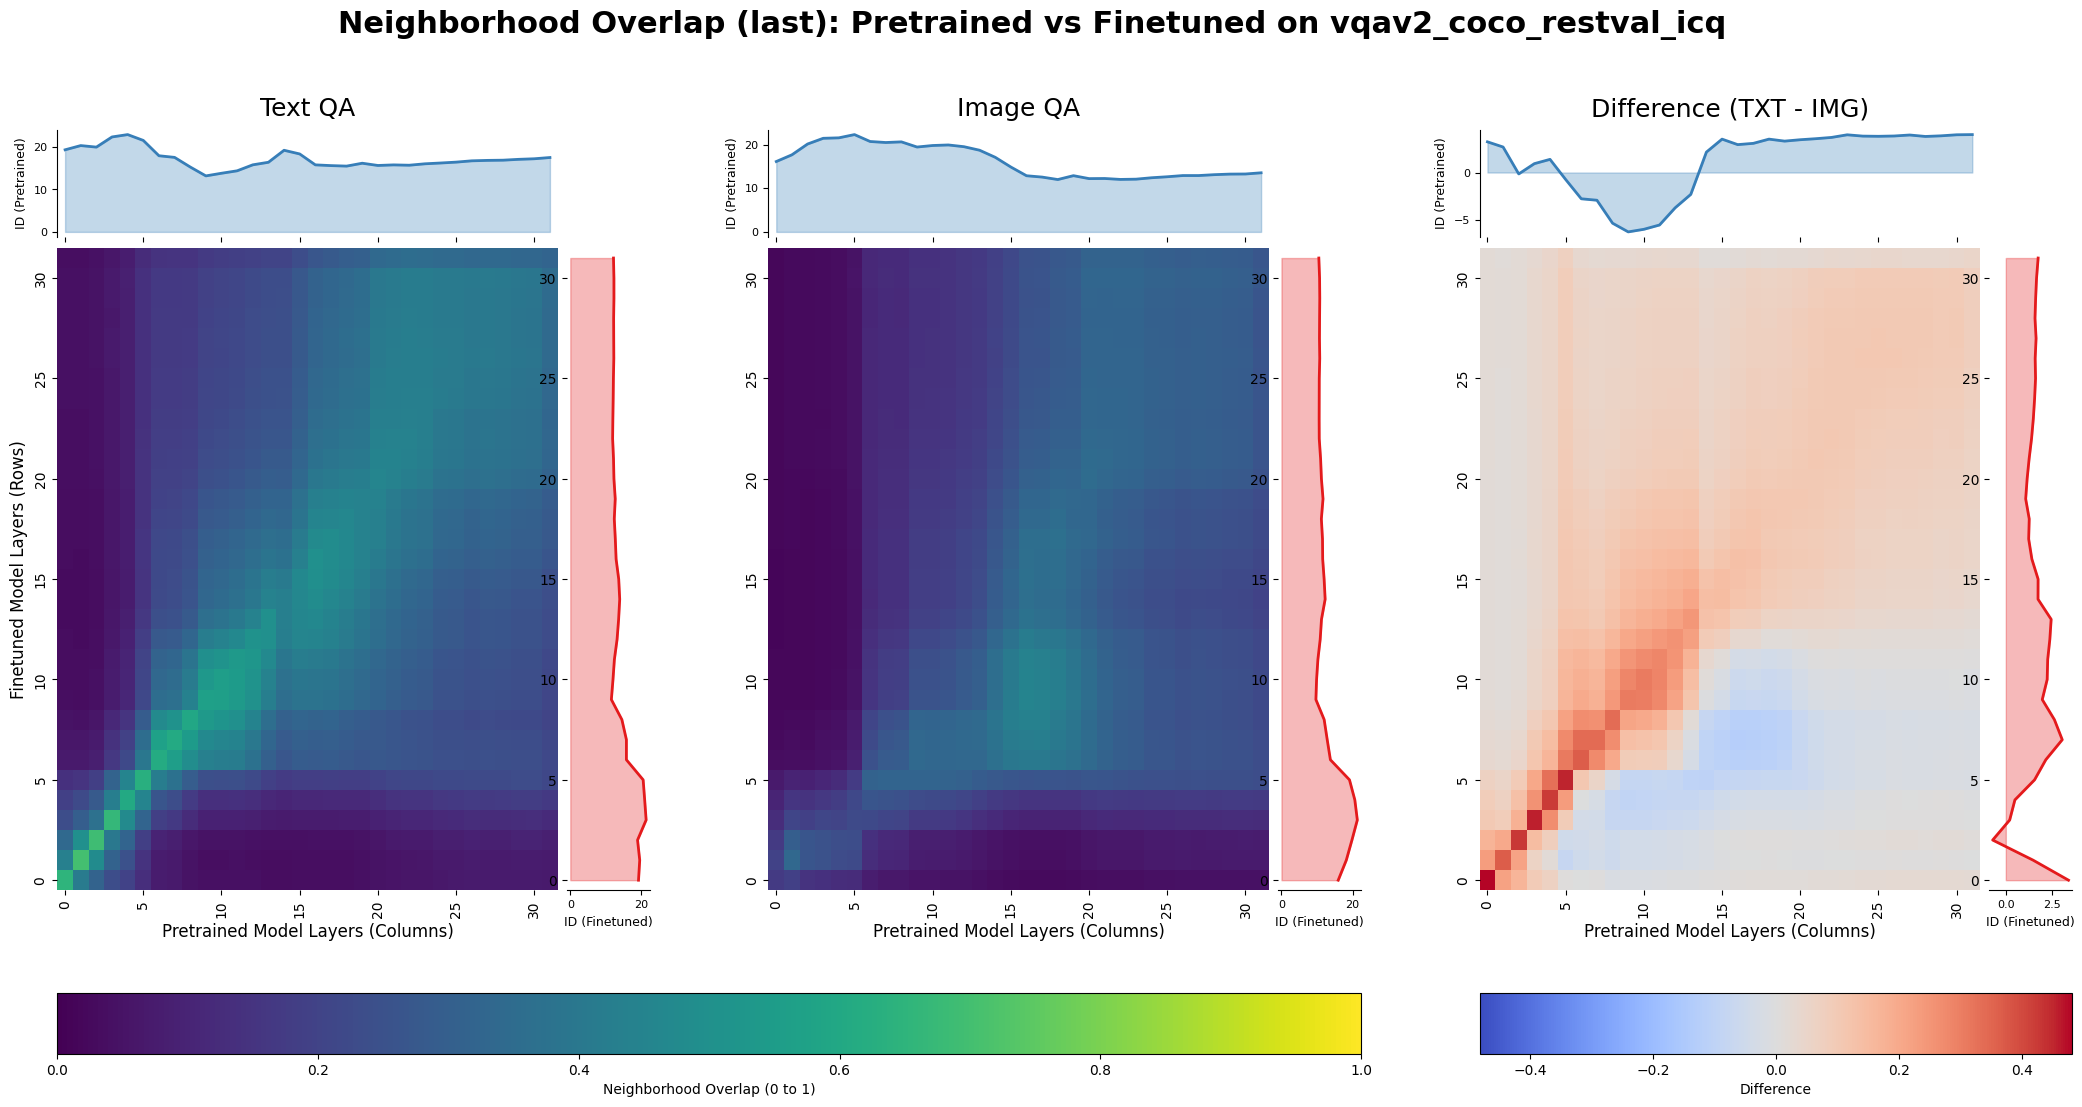

✅ Saved plot to ../plots/models_similarity/vqav2_coco_restval_icq_last_linear_cka_model_comparison.png


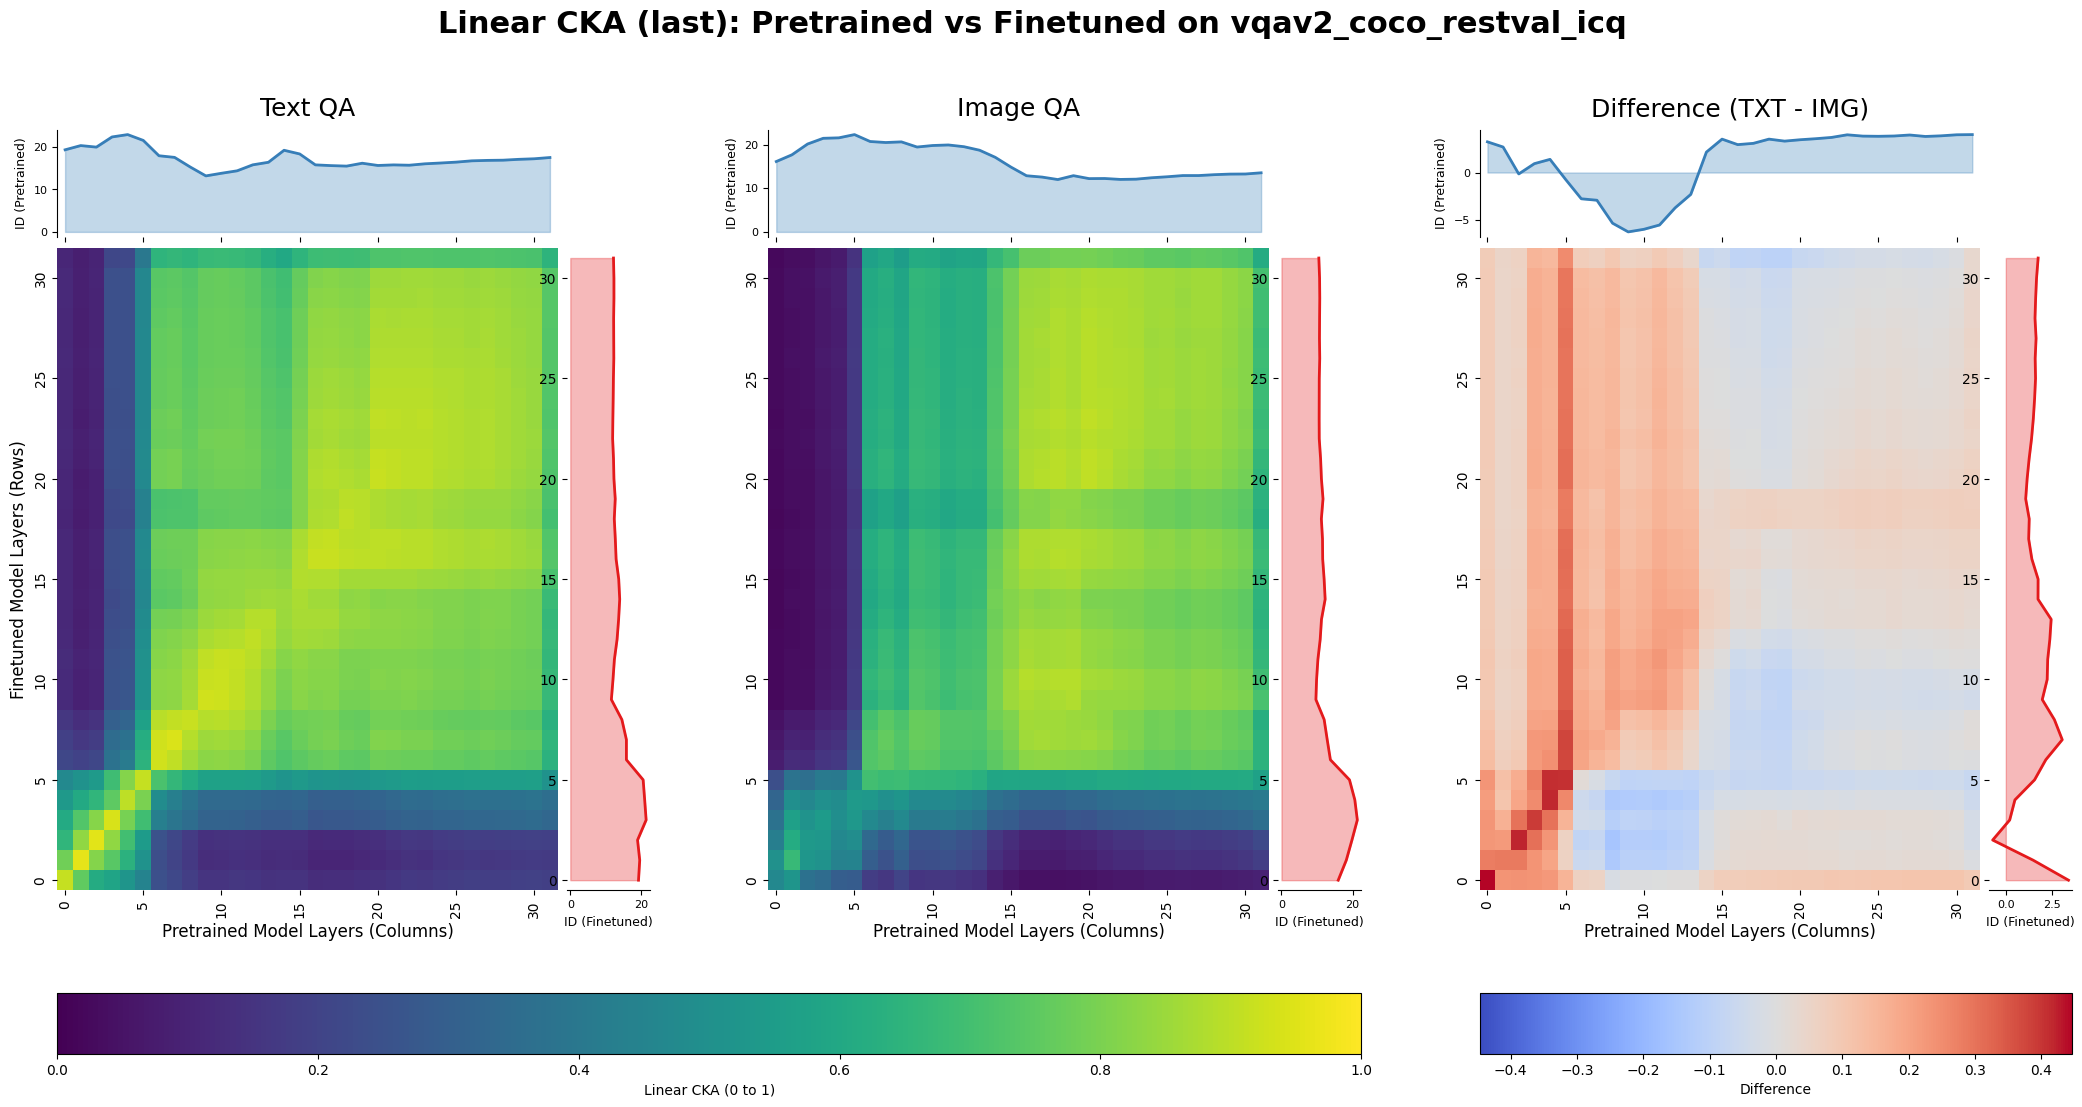

✅ Saved plot to ../plots/models_similarity/vqav2_coco_restval_icq_last_id_correlation_model_comparison.png


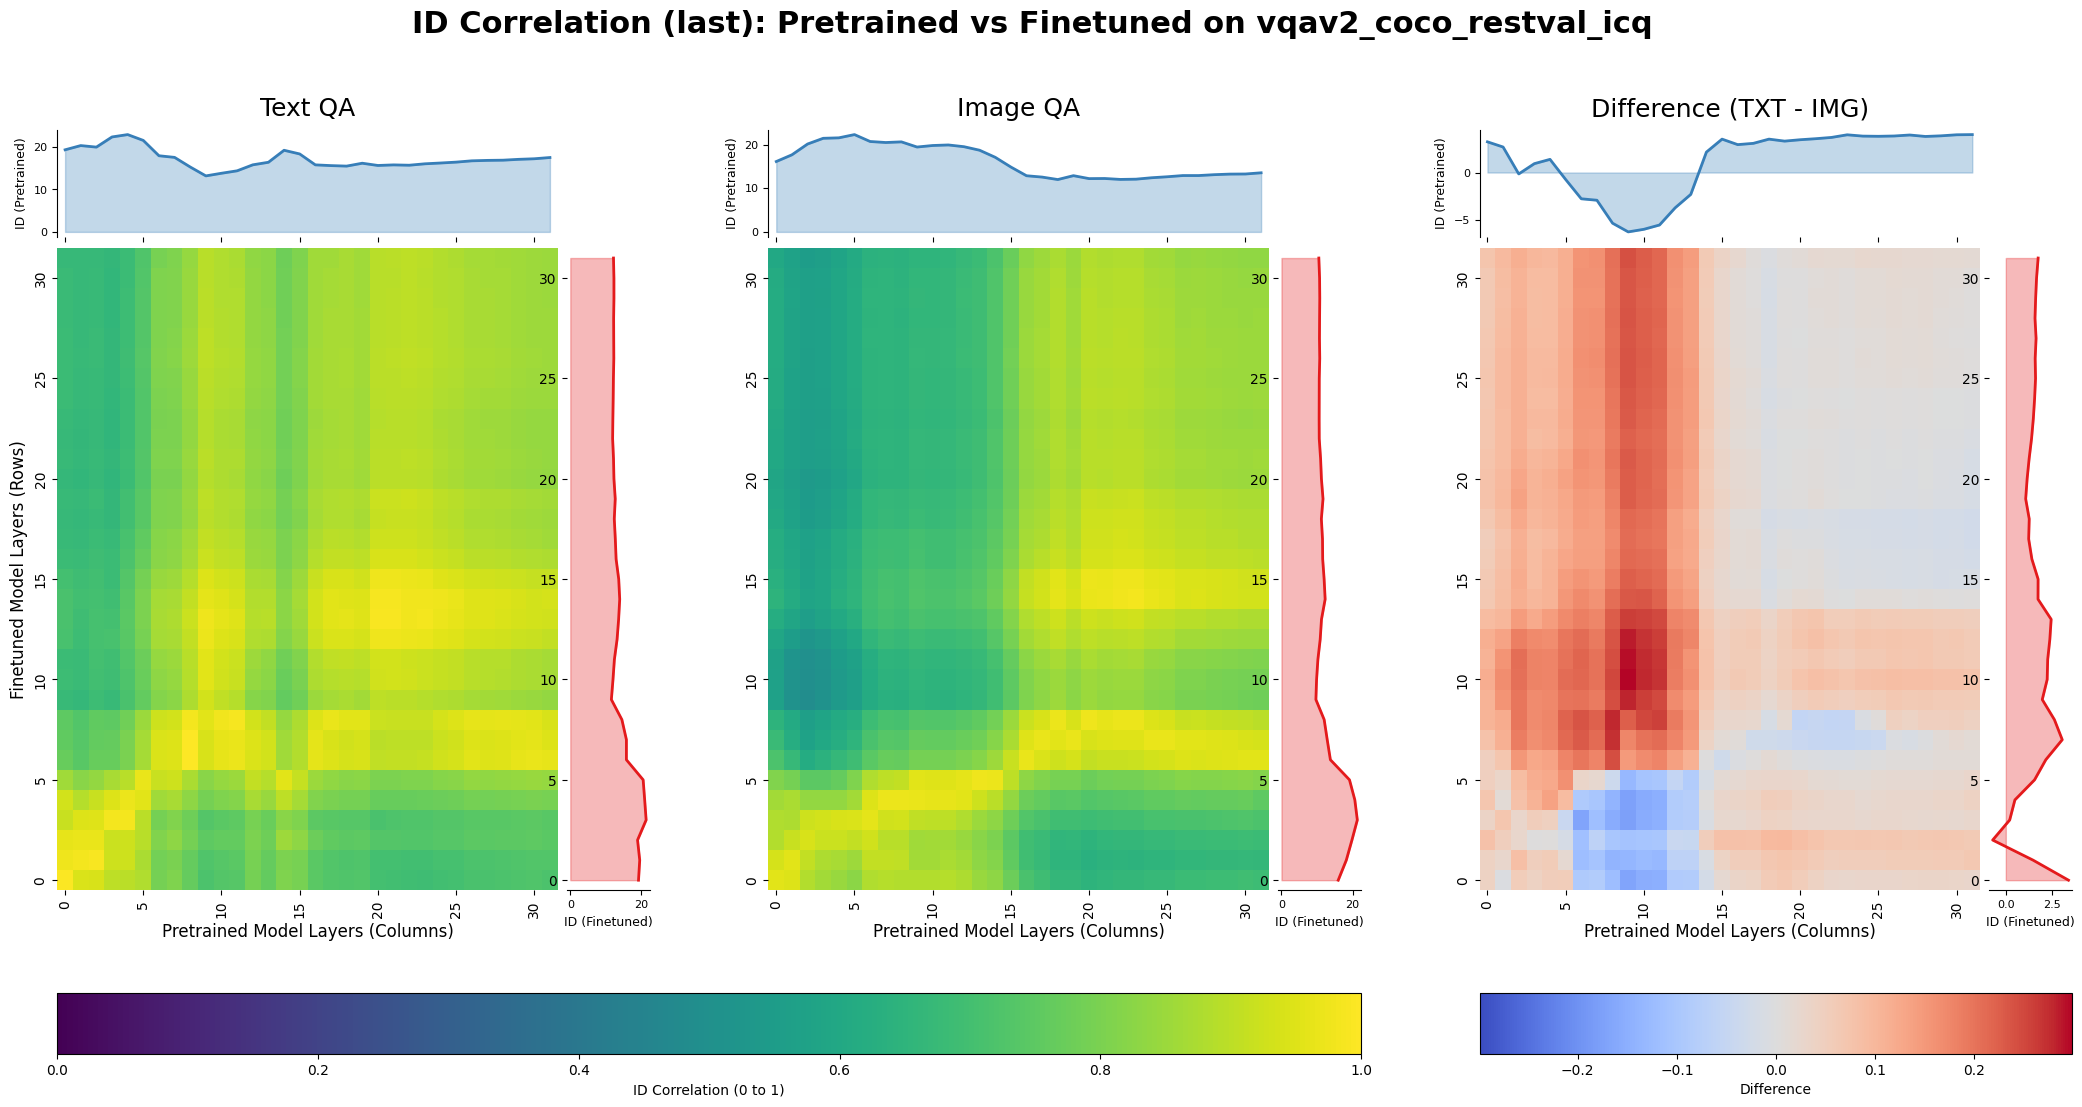

✅ Saved plot to ../plots/models_similarity/vqav2_coco_restval_icq_last_information_imbalance_model_comparison.png


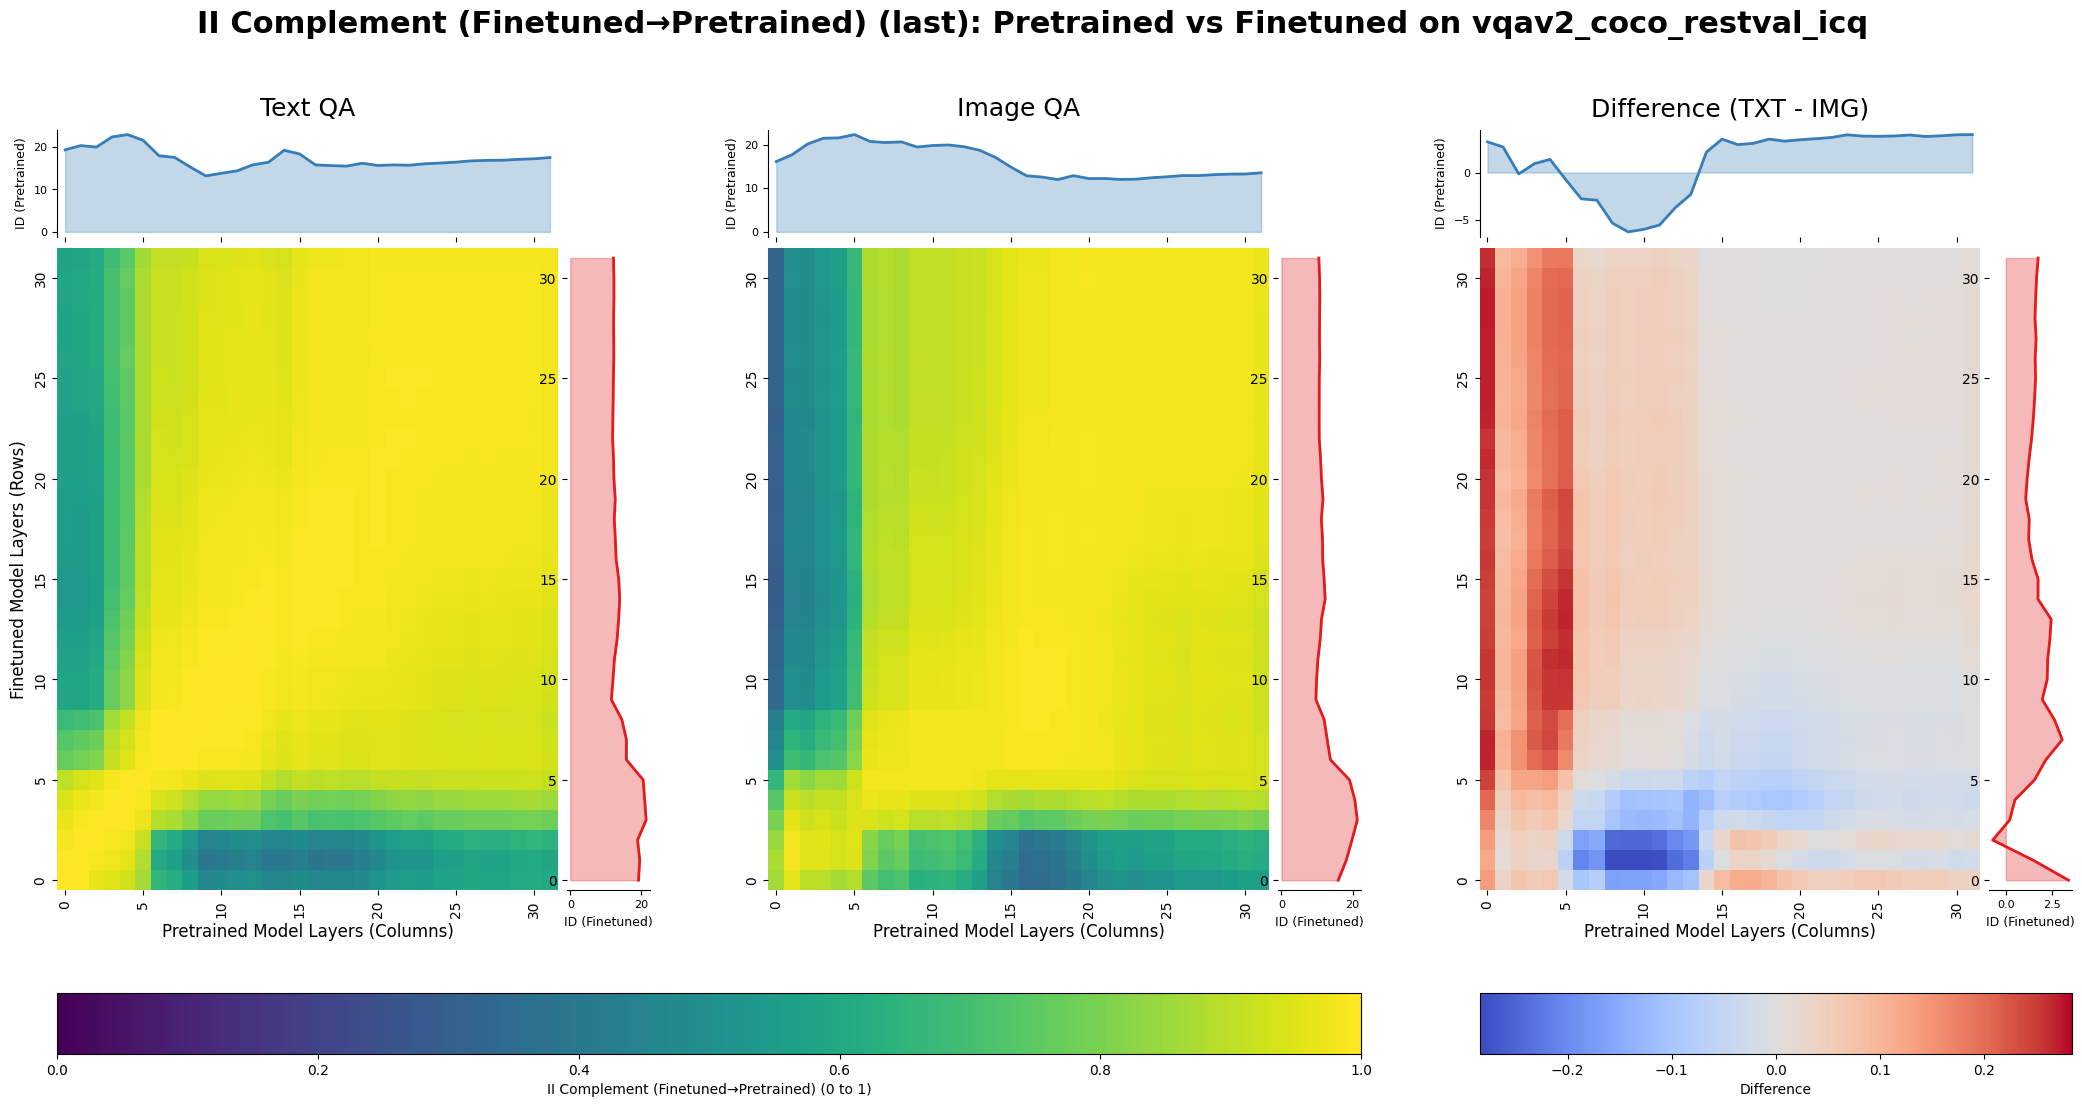

✅ Saved plot to ../plots/models_similarity/vqav2_coco_restval_icq_last_information_imbalance_reversed_model_comparison.png


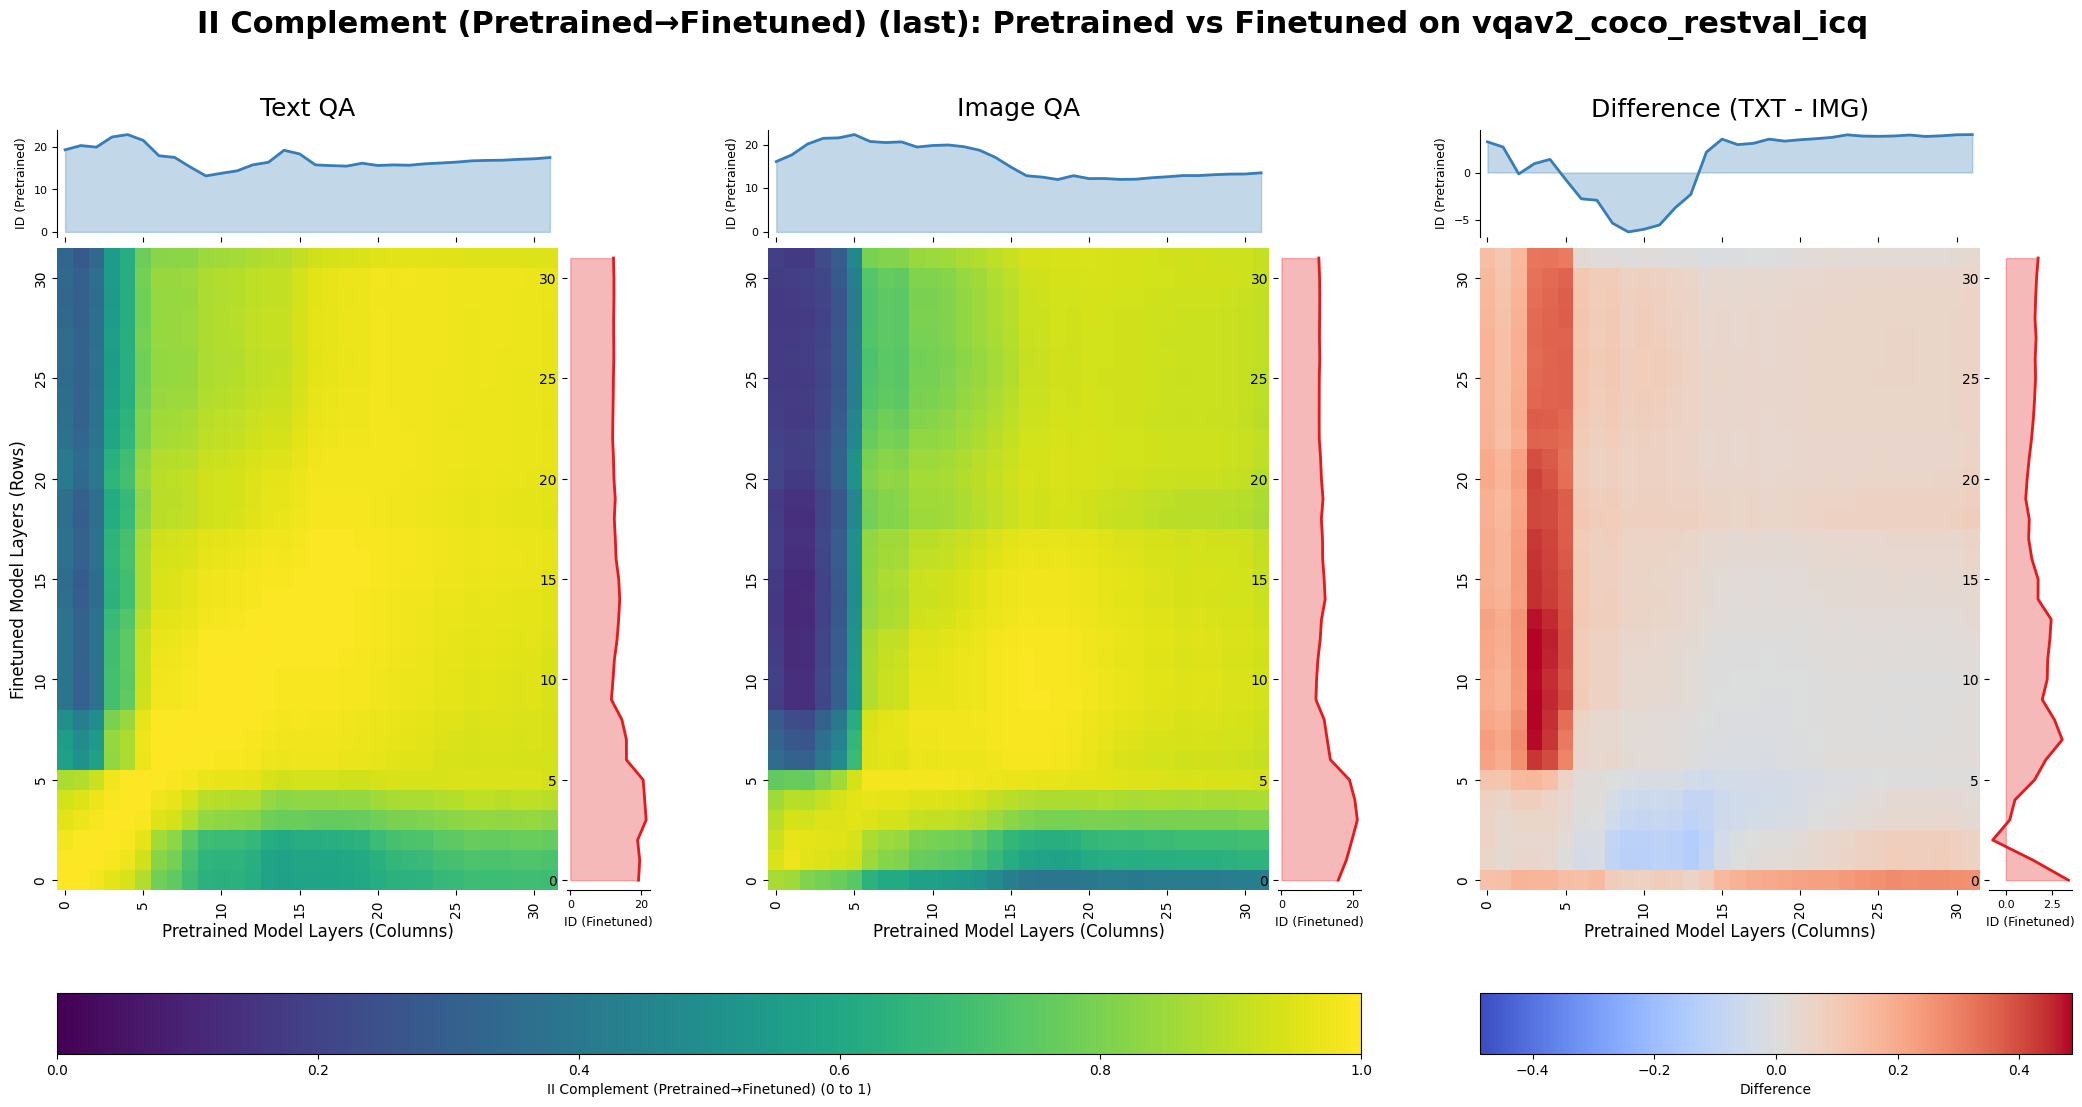

✅ Saved plot to ../plots/models_similarity/vqav2_coco_restval_icq_last_information_imbalance_mean_model_comparison.png


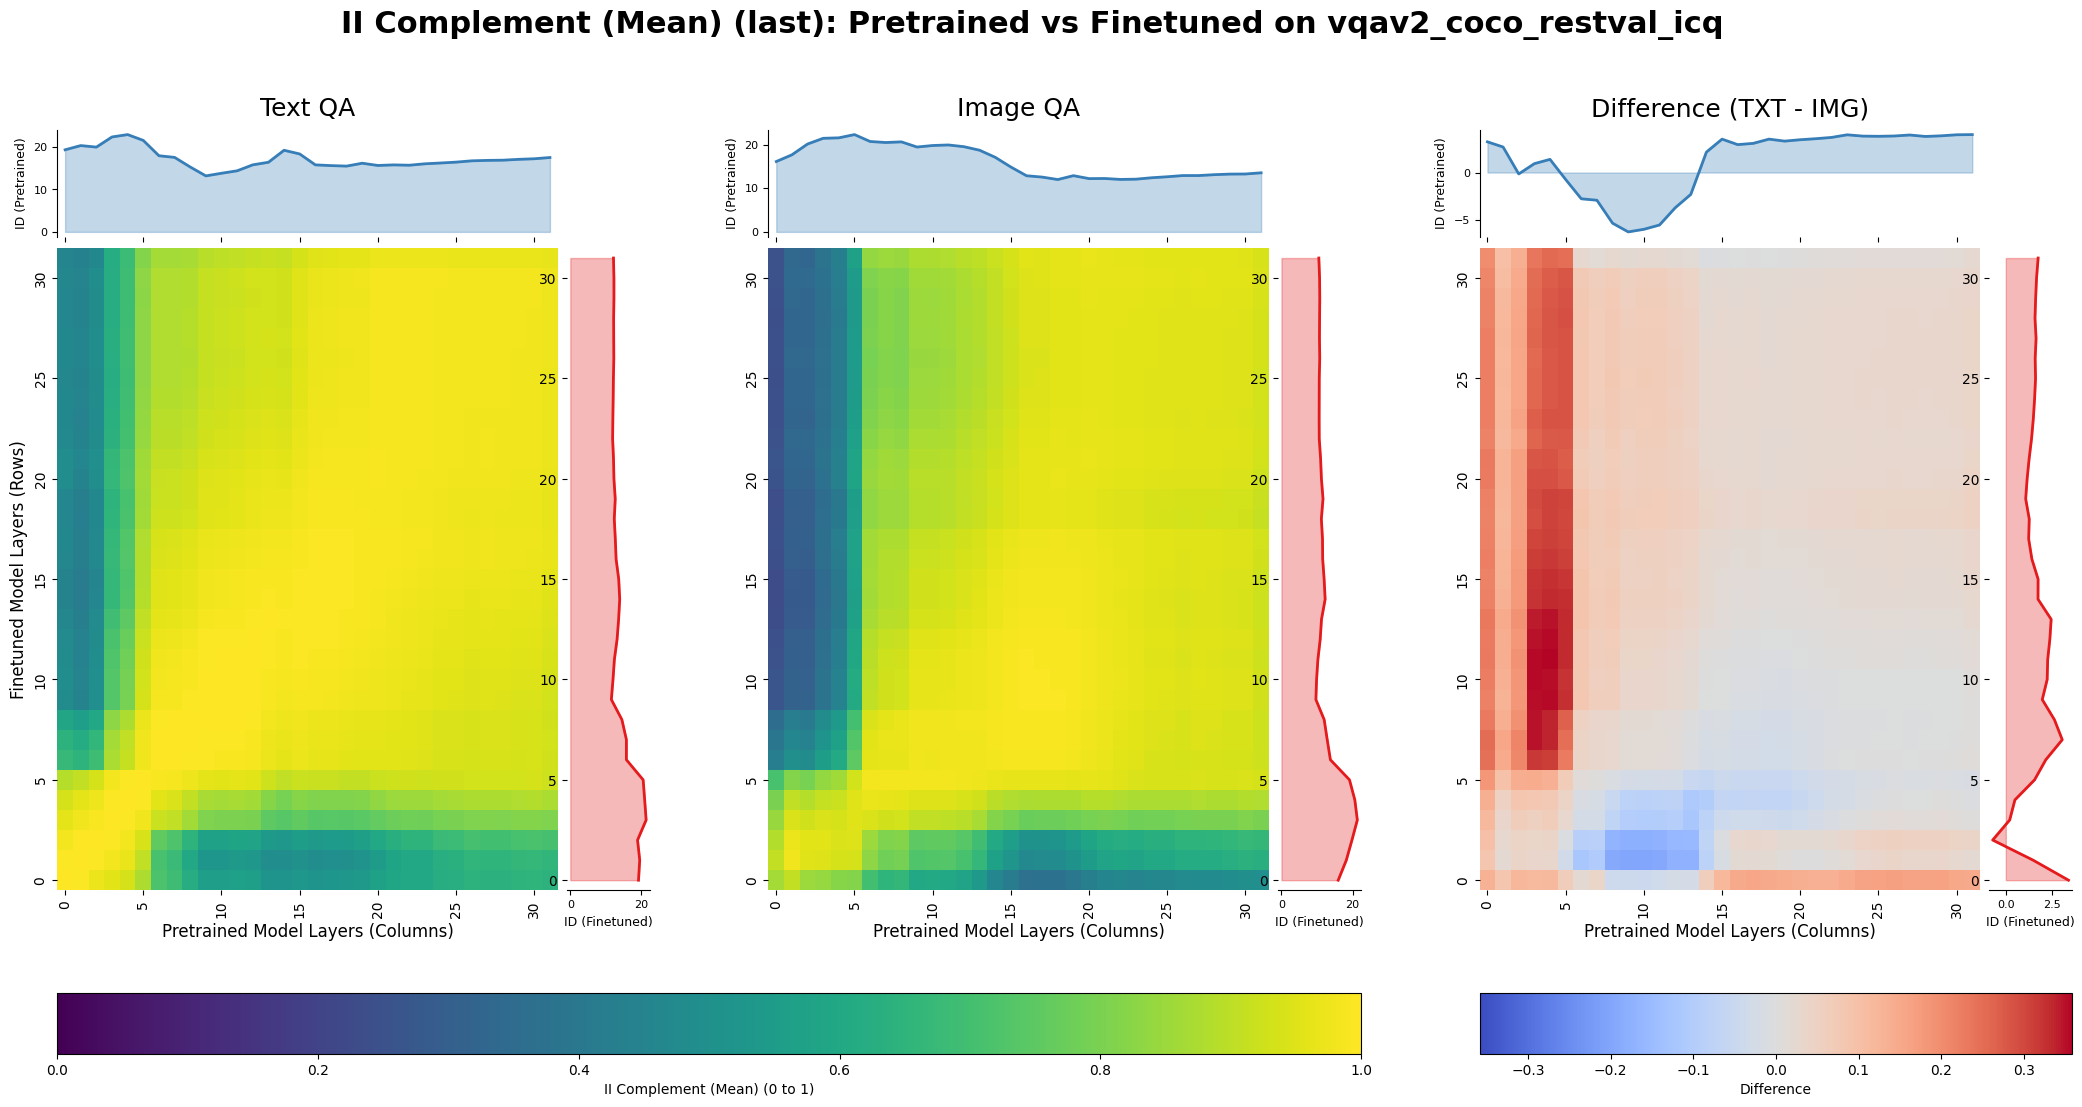

✅ Saved diagonal comparison to ../plots/models_similarity/vqav2_coco_restval_icq_last_diagonals_comparison.png


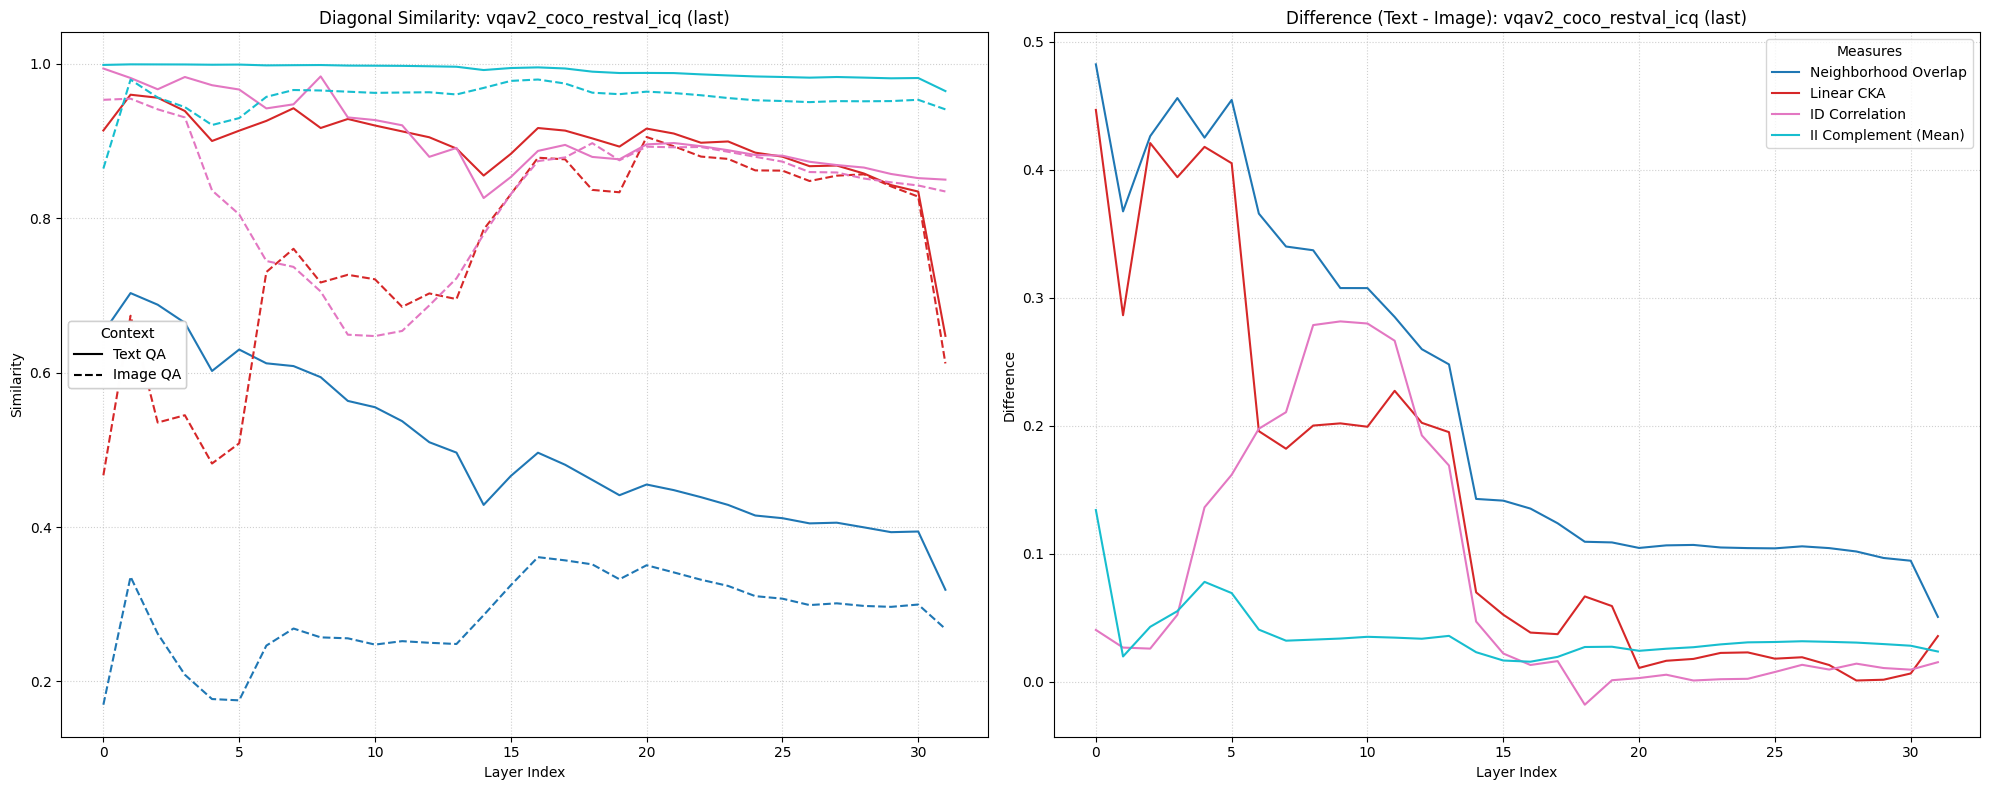

In [1]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pandas as pd
import numpy as np
from safetensors.torch import load_file

# ============================================================================
# CONFIGURATION
# ============================================================================

# Datasets to process
DATASET_NAMES = [
    "l11p/COCOQA-restval-ICQA",
    "l11p/VQAv2-COCO-restval-ICQ"
]

# Models Configuration (HuggingFace names)
MODELS = {
    "Pretrained": "l11p/llava-v1.5-7b-pretrained-liuhaotian",
    "Finetuned": "llava-hf/llava-1.5-7b-hf"
}

# Extract model IDs (used in filenames)
MODEL_IDS = {k: v.split('/')[-1] for k, v in MODELS.items()}
MODEL_A_ID = MODEL_IDS["Finetuned"]   # Rows in heatmap (Model A in script)
MODEL_B_ID = MODEL_IDS["Pretrained"]  # Columns in heatmap (Model B in script)

# Analysis Parameters
POOLING_METHODS = ["last"]
RESIDUAL_STREAM_TYPE = "output_layer"

MEASURES = {
    "neighborhood_overlap": "Neighborhood Overlap",
    "linear_cka": "Linear CKA",
    "id_correlation": "ID Correlation",
    "information_imbalance": "II Complement (Finetuned→Pretrained)",
    "information_imbalance_reversed": "II Complement (Pretrained→Finetuned)",
    "information_imbalance_mean": "II Complement (Mean)"
}

# Paths
RESULTS_DIR = Path("../results/model_comparison/similarities")
ID_RESULTS_DIR = Path("../results/model_comparison/intrinsic_dimension")
PLOTS_DIR = Path("../plots/models_similarity")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================================
# DATA LOADING FUNCTIONS
# ============================================================================

def load_similarity_data(dataset_prefix, split, measure_key, pooling_method):
    """
    Load similarity data.
    Filename format in models_similarity.py:
    {dataset_name}_{model_a_id}_vs_{model_b_id}_{pooling_method}_{measure_name}.safetensors
    where dataset_name = {dataset_prefix}_{split}
    """
    dataset_name = f"{dataset_prefix}_{split}"
    filename = f"{dataset_name}_{MODEL_A_ID}_vs_{MODEL_B_ID}_{pooling_method}_{measure_key}.safetensors"
    path = RESULTS_DIR / filename
    try:
        data = load_file(str(path))
        tensor = data[measure_key]
        val = tensor.cpu().numpy()
        # Invert Information Imbalance so higher is better (1 - II)
        if "information_imbalance" in measure_key:
            val = 1 - val
        return val
    except Exception as e:
        print(f"⚠️  Warning: Could not load similarity file: {filename}\n    Error: {e}")
        return None

def load_id_data(dataset_prefix, split, model_key, pooling_method):
    """
    Load Intrinsic Dimension data.
    Filename format in intrinsic_dimension.py:
    {model_id}_{current_dataset_name}_{pooling_method}_{residual_stream_type}_intrinsic_dimension.safetensors
    where current_dataset_name = {dataset_prefix}_{split}
    """
    model_id = MODEL_IDS[model_key]
    dataset_name = f"{dataset_prefix}_{split}"
    filename = f"{model_id}_{dataset_name}_{pooling_method}_{RESIDUAL_STREAM_TYPE}_intrinsic_dimension.safetensors"
    path = ID_RESULTS_DIR / filename
    
    try:
        data = load_file(str(path))
        tensor = data["intrinsic_dimension"]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"⚠️  Warning: Could not load ID file: {filename}\n    Error: {e}")
        return None

# ============================================================================
# PLOTTING FUNCTIONS
# ============================================================================

def plot_model_comparison(dataset_prefix, measure_key, measure_title, pooling_method, save_path):
    """
    Create a 3-panel comparison plot (Text, Image, Difference) with ID curves.
    """
    # Load similarity data
    sim_txt = load_similarity_data(dataset_prefix, "txt", measure_key, pooling_method)
    sim_img = load_similarity_data(dataset_prefix, "img", measure_key, pooling_method)
    
    if sim_txt is None or sim_img is None:
        print(f"❌ Skipping plot for {measure_title}: Missing similarity data.")
        return

    # Load ID data
    id_txt_pm = load_id_data(dataset_prefix, "txt", "Pretrained", pooling_method)
    id_txt_fm = load_id_data(dataset_prefix, "txt", "Finetuned", pooling_method)
    id_img_pm = load_id_data(dataset_prefix, "img", "Pretrained", pooling_method)
    id_img_fm = load_id_data(dataset_prefix, "img", "Finetuned", pooling_method)

    has_id_data = all(x is not None for x in [id_txt_pm, id_txt_fm, id_img_pm, id_img_fm])
    if not has_id_data:
        print(f"⚠️  Plotting {measure_title} without full Intrinsic Dimension data.")

    # Calculate differences
    sim_diff = sim_txt - sim_img
    id_pm_diff = (id_txt_pm - id_img_pm) if has_id_data else None
    id_fm_diff = (id_txt_fm - id_img_fm) if has_id_data else None
    
    max_diff = max(abs(np.nanmin(sim_diff)), abs(np.nanmax(sim_diff)))

    # Plot Setup
    fig = plt.figure(figsize=(26, 12 if has_id_data else 9))
    gs = gridspec.GridSpec(2, 3, height_ratios=[1, 0.08], width_ratios=[1, 1, 1], hspace=0.25, wspace=0.2)
    
    configs = [
        ("Text QA", sim_txt, id_txt_pm, id_txt_fm, "viridis", 0, 1),
        ("Image QA", sim_img, id_img_pm, id_img_fm, "viridis", 0, 1),
        ("Difference (TXT - IMG)", sim_diff, id_pm_diff, id_fm_diff, "coolwarm", -max_diff, max_diff)
    ]

    main_heatmaps = []

    for idx, (title, sim_data, id_pm, id_fm, cmap, vmin, vmax) in enumerate(configs):
        # Grid layout for ID curves vs Heatmap
        if has_id_data:
            gs_inner = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[0, idx], 
                                                      width_ratios=[6, 1], height_ratios=[1, 6], 
                                                      wspace=0.03, hspace=0.03)
            ax_top = fig.add_subplot(gs_inner[0, 0])
            ax_main = fig.add_subplot(gs_inner[1, 0])
            ax_right = fig.add_subplot(gs_inner[1, 1])
            
            ax_top.sharex(ax_main)
            ax_right.sharey(ax_main)
            
            # ID Curves
            # Top: Pretrained (Columns)
            x_centers = np.arange(len(id_pm)) + 0.5
            ax_top.plot(x_centers, id_pm, color='#377eb8', lw=2)
            ax_top.fill_between(x_centers, id_pm, 0, color='#377eb8', alpha=0.3)
            sns.despine(ax=ax_top, bottom=True, left=False)
            ax_top.tick_params(bottom=False, labelbottom=False, axis='y', labelsize=8)
            ax_top.set_ylabel('ID (Pretrained)', fontsize=9)
            
            # Right: Finetuned (Rows)
            y_centers = np.arange(len(id_fm)) + 0.5
            ax_right.plot(id_fm, y_centers, color='#e41a1c', lw=2)
            ax_right.fill_betweenx(y_centers, id_fm, 0, color='#e41a1c', alpha=0.3)
            sns.despine(ax=ax_right, left=True, bottom=False)
            ax_right.tick_params(left=False, labelleft=False, axis='x', labelsize=8)
            ax_right.set_xlabel('ID (Finetuned)', fontsize=9)
            
            ax_top.set_title(title, fontsize=18, pad=10, fontweight='medium')
        else:
            ax_main = fig.add_subplot(gs[0, idx])
            ax_main.set_title(title, fontsize=18, pad=10, fontweight='medium')

        # Heatmap
        hm = sns.heatmap(sim_data, ax=ax_main, cmap=cmap, vmin=vmin, vmax=vmax, 
                         center=0 if idx == 2 else None, square=False, cbar=False)
        if idx == 0 or idx == 2:
            main_heatmaps.append(hm.collections[0])

        # Axis labels
        ax_main.set_xlabel("Pretrained Model Layers (Columns)", fontsize=12)
        if idx == 0:
            ax_main.set_ylabel("Finetuned Model Layers (Rows)", fontsize=12)
        ax_main.invert_yaxis()
        
        # Ticks
        ticks = range(0, sim_data.shape[0], 5)
        ax_main.set_xticks([t + 0.5 for t in ticks])
        ax_main.set_xticklabels(ticks, fontsize=10)
        ax_main.set_yticks([t + 0.5 for t in ticks])
        ax_main.set_yticklabels(ticks, fontsize=10)

    # Colorbars
    cax_shared = fig.add_subplot(gs[1, 0:2])
    plt.colorbar(main_heatmaps[0], cax=cax_shared, orientation='horizontal', label=f"{measure_title} (0 to 1)")
    cax_diff = fig.add_subplot(gs[1, 2])
    plt.colorbar(main_heatmaps[1], cax=cax_diff, orientation='horizontal', label=f"Difference")

    plt.suptitle(f"{measure_title} ({pooling_method}): Pretrained vs Finetuned on {dataset_prefix}", fontsize=22, fontweight='bold', y=0.98)
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"✅ Saved plot to {save_path}")
    plt.show()

def plot_diagonal_comparison(dataset_prefix, pooling_method, save_path):
    """
    Plot diagonal similarities and differences.
    """
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    
    # Filter measures
    measures_to_plot = {}
    has_mean = "information_imbalance_mean" in MEASURES
    for key, title in MEASURES.items():
        if has_mean and key in ["information_imbalance", "information_imbalance_reversed"]:
            continue
        measures_to_plot[key] = title
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(measures_to_plot)))
    
    for (key, title), color in zip(measures_to_plot.items(), colors):
        sim_txt = load_similarity_data(dataset_prefix, "txt", key, pooling_method)
        sim_img = load_similarity_data(dataset_prefix, "img", key, pooling_method)
        
        if sim_txt is None or sim_img is None:
            continue
            
        diag_txt = np.diag(sim_txt)
        diag_img = np.diag(sim_img)
        diag_diff = diag_txt - diag_img
        
        x_axis = range(len(diag_txt))
        
        # Plot 1: Diagonals
        axes[0].plot(x_axis, diag_txt, linestyle='-', color=color, label=title)
        axes[0].plot(x_axis, diag_img, linestyle='--', color=color)
        
        # Plot 2: Difference
        axes[1].plot(x_axis, diag_diff, linestyle='-', color=color, label=title)

    # Styles
    axes[0].set_title(f"Diagonal Similarity: {dataset_prefix} ({pooling_method})")
    axes[0].set_xlabel("Layer Index")
    axes[0].set_ylabel("Similarity")
    
    # Legends
    axes[0].legend(title="Measures", loc='upper left', bbox_to_anchor=(0, 1))
    
    from matplotlib.lines import Line2D
    custom_lines = [
        Line2D([0], [0], color='black', linestyle='-', label='Text QA'),
        Line2D([0], [0], color='black', linestyle='--', label='Image QA')
    ]
    # Add context legend (manually placed to avoid overlap)
    leg2 = axes[0].legend(handles=custom_lines, loc='upper left', bbox_to_anchor=(0, 0.6), title="Context")
    axes[0].add_artist(axes[0].get_legend()) # Re-add first legend
    axes[0].add_artist(leg2)
    axes[0].grid(True, linestyle=':', alpha=0.6)

    axes[1].set_title(f"Difference (Text - Image): {dataset_prefix} ({pooling_method})")
    axes[1].set_xlabel("Layer Index")
    axes[1].set_ylabel("Difference")
    axes[1].legend(title="Measures")
    axes[1].grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"✅ Saved diagonal comparison to {save_path}")
    plt.show()

# ============================================================================
# MAIN EXECUTION
# ============================================================================

def main():
    for dataset_name in DATASET_NAMES:
        dataset_prefix = dataset_name.split('/')[-1].replace('.', '_').replace('-', '_').lower()
        print(f"\n{'='*80}\n📊 Processing Dataset: {dataset_name} ({dataset_prefix})\n{'='*80}")
        
        for pooling in POOLING_METHODS:
            print(f"\n🔍 Pooling Method: {pooling}\n{'-'*80}")
            
            # 1. Heatmaps for each measure
            for key, title in MEASURES.items():
                save_path = PLOTS_DIR / f"{dataset_prefix}_{pooling}_{key}_model_comparison.png"
                plot_model_comparison(dataset_prefix, key, title, pooling, save_path)
            
            # 2. Diagonal Comparison
            diag_save_path = PLOTS_DIR / f"{dataset_prefix}_{pooling}_diagonals_comparison.png"
            plot_diagonal_comparison(dataset_prefix, pooling, diag_save_path)

if __name__ == '__main__':
    main()